# PolicyLens Duplicate and Overlap Manual Review

This notebook creates a reproducible manual-review workflow for exact duplicate text, near-duplicate candidates, duplicate records, and cross-dataset row-ID overlap in the three Open Government consultation datasets.

**Important boundaries:**
- This notebook does **not** delete records, merge datasets, alter raw data, train models, or fabricate human labels.
- All review decision and notes fields are intentionally left blank for subsequent human annotator evaluation.
- All counts and evidence summaries are calculated directly from local artifacts.

## 1. Setup and Existing Artifact Inspection

We inspect and load the outputs of `01_dataset_audit_and_cleaning.ipynb`: interim response-text entries, duplicate candidates, near-duplicate candidates, row-ID overlap output, cleaned source copies, and audit reports.

In [1]:
import json
import re
from collections import Counter
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 4)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERIM = PROJECT_ROOT / "data" / "interim"
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
REVIEW_DIR = INTERIM / "review"
REVIEW_DIR.mkdir(parents=True, exist_ok=True)

artifact_paths = {
    "duplicate_text_entries": INTERIM / "government_duplicate_text_entries.csv",
    "near_duplicate_candidates": INTERIM / "government_near_duplicate_candidates.csv",
    "id_overlap": INTERIM / "government_id_overlap.csv",
    "response_text_entries": INTERIM / "government_response_text_entries.csv",
    "inventory": REPORTS / "data_inventory.csv",
    "overlap_report": REPORTS / "dataset_overlap_report.md",
    "questionnaire_clean": PROCESSED / "get_involved_questionnaire_2017_18_source_clean.csv",
    "individual_clean": PROCESSED / "individual_comments_2016_18_source_clean.csv",
    "compilation_clean": PROCESSED / "consultation_compilation_2017_18_source_clean.csv",
}

for name, path in artifact_paths.items():
    assert path.exists(), f"Missing required artifact: {path}"

artifact_summary = pd.DataFrame([
    {"artifact": name, "relative_path": path.relative_to(PROJECT_ROOT).as_posix(), "size_bytes": path.stat().st_size}
    for name, path in artifact_paths.items()
])
artifact_summary

,artifact,relative_path,size_bytes
0,duplicate_text_entries,data/interim/government_duplicate_text_entries.csv,99541
1,near_duplicate_candidates,data/interim/government_near_duplicate_candidates.csv,8603
2,id_overlap,data/interim/government_id_overlap.csv,353
3,response_text_entries,data/interim/government_response_text_entries.csv,5560079
4,inventory,reports/data_inventory.csv,2455
5,overlap_report,reports/dataset_overlap_report.md,1472
6,questionnaire_clean,data/processed/get_involved_questionnaire_2017_18_source_clean.csv,4015948
7,individual_clean,data/processed/individual_comments_2016_18_source_clean.csv,79471
8,compilation_clean,data/processed/consultation_compilation_2017_18_source_clean.csv,3598665


In [2]:
duplicate_text_entries = pd.read_csv(artifact_paths["duplicate_text_entries"], keep_default_na=False)
near_duplicate_candidates = pd.read_csv(artifact_paths["near_duplicate_candidates"], keep_default_na=False)
id_overlap = pd.read_csv(artifact_paths["id_overlap"], keep_default_na=False)
response_text_entries = pd.read_csv(artifact_paths["response_text_entries"], keep_default_na=False)
inventory = pd.read_csv(artifact_paths["inventory"], keep_default_na=False)

clean_data = {
    "get_involved_questionnaire_2017_18": pd.read_csv(artifact_paths["questionnaire_clean"], keep_default_na=False, dtype=str),
    "individual_comments_2016_18": pd.read_csv(artifact_paths["individual_clean"], keep_default_na=False, dtype=str),
    "consultation_compilation_2017_18": pd.read_csv(artifact_paths["compilation_clean"], keep_default_na=False, dtype=str),
}

schema_rows = []
for name, df in {
    "government_duplicate_text_entries.csv": duplicate_text_entries,
    "government_near_duplicate_candidates.csv": near_duplicate_candidates,
    "government_id_overlap.csv": id_overlap,
    "government_response_text_entries.csv": response_text_entries,
}.items():
    schema_rows.append({
        "file": name,
        "rows": len(df),
        "columns": len(df.columns),
        "column_names": ", ".join(df.columns),
    })
pd.DataFrame(schema_rows)

,file,rows,columns,column_names
0,government_duplicate_text_entries.csv,596,6,"dataset_name, source_row_index, source_row_number, column_name, text_key, text_sample_redacted"
1,government_near_duplicate_candidates.csv,19,9,"left_dataset, left_row, left_column, right_dataset, right_row, right_column, similarity, left_sample_redacted, right_sample_redacted"
2,government_id_overlap.csv,1,6,"left_dataset, left_id_column, right_dataset, right_id_column, overlapping_ids, sample_ids"
3,government_response_text_entries.csv,14135,6,"dataset_name, source_row_index, source_row_number, column_name, text_key, text_sample_redacted"


In [3]:
display(duplicate_text_entries.head(10))
display(near_duplicate_candidates.head(10))
display(id_overlap)
print((REPORTS / "dataset_overlap_report.md").read_text(encoding="utf-8")[:2000])

,dataset_name,source_row_index,source_row_number,column_name,text_key,text_sample_redacted
0,consultation_compilation_2017_18,3852,3853,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",#name?,#NAME?
1,consultation_compilation_2017_18,4931,4932,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",#name?,#NAME?
2,get_involved_questionnaire_2017_18,4528,4529,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government that drive your inte...",*****personal information removed*****,*****Personal Information Removed*****
3,get_involved_questionnaire_2017_18,4748,4749,Q9R. Other (please specify)9,*****personal information removed*****,*****Personal Information Removed*****
4,get_involved_questionnaire_2017_18,964,965,Q11R. Other: I can..,.,.
5,get_involved_questionnaire_2017_18,964,965,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government that drive your inte...",.,.
6,get_involved_questionnaire_2017_18,3525,3526,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government that drive your inte...",.,.
7,get_involved_questionnaire_2017_18,5516,5517,Q19R. Other (please specify)19,.,.
8,get_involved_questionnaire_2017_18,5516,5517,Q4R. Other (please specify)6,.,.
9,get_involved_questionnaire_2017_18,5516,5517,Q6R. Other (please specify),.,.


,left_dataset,left_row,left_column,right_dataset,right_row,right_column,similarity,left_sample_redacted,right_sample_redacted
0,consultation_compilation_2017_18,2564,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2563,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.968,"15 DAYS LEFT to NOMINATE your deserving Community Leader, City Administrative Leader or City Council Leader's contributions with Open Data for Canada's Open...","15 DAYS LEFT to NOMINATE your deserving Community Leader, City Administrative Leader or City Council Leader's contributions with Open Data for Canada's Open..."
1,consultation_compilation_2017_18,2680,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2682,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.921,@columgw @OpenGovCan @TBS_Canada @jaimieboyd @MelRobrt @AlexBenay @kentdaitken Awesome. Congrats!,@columgw @OpenGovCan @TBS_Canada @jaimieboyd @MelRobrt @AlexBenay @kentdaitken Welcome back!
2,consultation_compilation_2017_18,3231,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,4756,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.984,environmental impact assesments,Environmental impact assessments
3,consultation_compilation_2017_18,4406,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,4407,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.988,Financial transparency and accountability,"financial transparency and accountability,"
4,consultation_compilation_2017_18,3321,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,3322,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.928,Great message in this opengovpart article on building bipartisan buy-in to protect openness (including shout-out to #OpenGovCan!) https://t.co/GsuEF6MUUQ ht...,Great message in this opengovpart article on building bipartisan buy-in to protect openness (including shout-out to #OpenGovCan!) https://t.co/RI3gddihLN ht...
5,consultation_compilation_2017_18,2731,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2732,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.962,Happy I made it to #CodeAcrossTO in time to hear the challenge presentations from all theee levels of open government (@OpenGovON/@OpenGovCan/@Open_TO) and ...,Happy I made it to #CodeAcrossTO in time to hear the challenge presentations from all three levels of open government (@OpenGovON/@OpenGovCan/@Open_TO) and ...
6,consultation_compilation_2017_18,2723,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2722,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.976,Happy #OpenDataDay / #ODD18. Be sure to check out any #OpenData events in your community! @OpenGovON @Open_TO @OpenGovCan,Happy #OpenDataDay / #ODD18. Be sure to check out any #OpenData events in your community! @OpenGovON @Open_TO @OpenGovCan @open
7,get_involved_questionnaire_2017_18,4577,Q14. Please tell us why:,get_involved_questionnaire_2017_18,3652,Q14. Please tell us why:,0.970,have not been to the website yet,"have not been to the website, yet."
8,get_involved_question

,left_dataset,left_id_column,right_dataset,right_id_column,overlapping_ids,sample_ids
0,individual_comments_2016_18,Row\nRangée,consultation_compilation_2017_18,Row/Ligne,145,"[""1"", ""10"", ""100"", ""101"", ""102"", ""103"", ""104"", ""105"", ""106"", ""107"", ""108"", ""109"", ""11"", ""110"", ""111"", ""112"", ""113"", ""114"", ""115"", ""116""]"


# Dataset Overlap Report

Generated by `notebooks/01_dataset_audit_and_cleaning.ipynb`.

## Schema Overlap

| left_dataset | right_dataset | left_columns | right_columns | common_normalized_columns | common_column_names |
| --- | --- | --- | --- | --- | --- |
| get_involved_questionnaire_2017_18 | individual_comments_2016_18 | 98 | 19 | 0 | [] |
| get_involved_questionnaire_2017_18 | consultation_compilation_2017_18 | 98 | 63 | 0 | [] |
| individual_comments_2016_18 | consultation_compilation_2017_18 | 19 | 63 | 2 | ["source", "source language"] |

## Identifier Overlap

| left_dataset | left_id_column | right_dataset | right_id_column | overlapping_ids | sample_ids |
| --- | --- | --- | --- | --- | --- |
| individual_comments_2016_18 | Row Rangée | consultation_compilation_2017_18 | Row/Ligne | 145 | ["1", "10", "100", "101", "102", "103", "104", "105", "106", "107", "108", "109", "11", "110", "111", "112", "113", "114", "115", "116"] |

## Exact Duplicate Response Text

Duplicate res

## 2. Duplicate Count Reconciliation

Different audit scripts and reports reported seemingly divergent duplicate counts because they measured different statistical units:

1. **Within-column extra occurrences (298 total across datasets)**:
   Calculated within each individual response-like column: `total_column_entries - unique_text_values`.
   - Consultation Compilation: 34
   - Get Involved Questionnaire: 264
   - Individual Comments: 0
   This matches `data_inventory.csv`'s `duplicate_text_entries` column.

2. **Across-fields extra occurrences within dataset (382 total)**:
   Calculated across all response-like fields combined within each dataset: `total_dataset_entries - unique_text_values`.
   - Consultation Compilation: 35
   - Get Involved Questionnaire: 347
   - Individual Comments: 0
   This is higher for the questionnaire because identical responses (e.g. `'N/A'`, `'none'`) appear across different survey question columns.

3. **Rows in within-dataset duplicate groups (560 total)**:
   The total count of all rows whose normalized response text appears at least twice within the same dataset.
   - Consultation Compilation: 62
   - Get Involved Questionnaire: 498
   - Individual Comments: 0

4. **Rows in global duplicate groups (596 total)**:
   The total count of all rows whose normalized text appears at least twice across the entire pooled collection of all three datasets.
   - Consultation Compilation: 80
   - Get Involved Questionnaire: 514
   - Individual Comments: 2
   This is the exact row count of `government_duplicate_text_entries.csv`.

5. **Exact duplicate records (13 extra, 14 total in group)**:
   Full row records that are identical across all original data columns. Only `individual_comments_2016_18` contains 14 trailing all-blank rows preserved from the source file.

The reconciliation table below aligns all these metrics side by side.

In [4]:
def duplicate_count_reconciliation(entries: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    # 1. Within-column extra occurrences (matches data_inventory.csv)
    within_column = (
        entries.groupby(["dataset_name", "column_name"])
        .apply(lambda group: len(group) - group["text_key"].nunique(dropna=False), include_groups=False)
        .reset_index(name="extra_occurrences_within_column")
    )
    within_column_by_dataset = (
        within_column.groupby("dataset_name")["extra_occurrences_within_column"]
        .sum()
        .reset_index(name="inventory_within_column_extra_occurrences")
    )

    # 2. Across-fields extra occurrences within dataset
    across_dataset = (
        entries.groupby("dataset_name")
        .apply(lambda group: len(group) - group["text_key"].nunique(dropna=False), include_groups=False)
        .reset_index(name="extra_occurrences_across_response_fields")
    )

    # 3. Rows in within-dataset duplicate groups
    within_ds_dupe_rows = (
        entries.groupby("dataset_name")
        .apply(lambda group: group[group["text_key"].duplicated(keep=False)], include_groups=False)
        .reset_index()
    )
    rows_in_within_ds_groups = (
        within_ds_dupe_rows.groupby("dataset_name")
        .size()
        .reset_index(name="rows_in_within_dataset_duplicate_groups")
    )

    # 4. Rows in global duplicate groups (from government_duplicate_text_entries.csv)
    global_dupe_rows = entries[entries["text_key"].duplicated(keep=False)].copy()
    rows_in_global_groups = (
        global_dupe_rows.groupby("dataset_name")
        .size()
        .reset_index(name="rows_in_global_duplicate_groups")
    )

    # Group table for global duplicate text
    group_table = (
        global_dupe_rows.groupby("text_key")
        .agg(
            duplicate_group_size=("text_key", "size"),
            datasets=("dataset_name", lambda values: ", ".join(sorted(set(values)))),
            columns=("column_name", lambda values: " | ".join(sorted(set(values))[:8])),
        )
        .reset_index()
    )
    group_table["duplicate_group_id"] = [f"exact_text_{index + 1:05d}" for index in range(len(group_table))]

    groups_by_dataset = (
        global_dupe_rows.merge(group_table[["text_key", "duplicate_group_id"]], on="text_key", how="left")
        .groupby("dataset_name")["duplicate_group_id"]
        .nunique()
        .reset_index(name="duplicate_groups_touched")
    )

    # Combine all metrics
    all_datasets = pd.DataFrame({"dataset_name": sorted(entries["dataset_name"].unique())})
    reconciliation = all_datasets
    for table in [
        within_column_by_dataset,
        across_dataset,
        rows_in_within_ds_groups,
        rows_in_global_groups,
        groups_by_dataset,
    ]:
        reconciliation = reconciliation.merge(table, on="dataset_name", how="left")
    reconciliation = reconciliation.fillna(0)
    for column in reconciliation.columns:
        if column != "dataset_name":
            reconciliation[column] = reconciliation[column].astype(int)
    return reconciliation, group_table


reconciliation_df, exact_text_group_table = duplicate_count_reconciliation(response_text_entries)
display(reconciliation_df)
display(exact_text_group_table.sort_values("duplicate_group_size", ascending=False).head(20))

,dataset_name,inventory_within_column_extra_occurrences,extra_occurrences_across_response_fields,rows_in_within_dataset_duplicate_groups,rows_in_global_duplicate_groups,duplicate_groups_touched
0,consultation_compilation_2017_18,34,35,62,80,45
1,get_involved_questionnaire_2017_18,264,347,498,514,167
2,individual_comments_2016_18,0,0,0,2,2


,text_key,duplicate_group_size,datasets,columns,duplicate_group_id
114,no,42,get_involved_questionnaire_2017_18,Q18. If you have knowledge or experience with a open government topic that you would be willing to share please tell us about it: | Q8. Did we miss anything...,exact_text_00115
45,email,21,get_involved_questionnaire_2017_18,Q12R. Other (please specify),exact_text_00046
186,yes,13,"consultation_compilation_2017_18, get_involved_questionnaire_2017_18","Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ) | Q18. If you have knowledge or experience with a o...",exact_text_00187
10,all of the above,12,get_involved_questionnaire_2017_18,Q2R. Other (please specify) | Q4R. Other (please specify)6 | Q6R. Other (please specify),exact_text_00011
70,health care,12,get_involved_questionnaire_2017_18,Q18. If you have knowledge or experience with a open government topic that you would be willing to share please tell us about it: | Q19R. Other (please spec...,exact_text_00071
86,immigration,11,"consultation_compilation_2017_18, get_involved_questionnaire_2017_18","Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ) | Q18. If you have knowledge or experience with a o...",exact_text_00087
117,non,10,get_involved_questionnaire_2017_18,Q18. If you have knowledge or experience with a open government topic that you would be willing to share please tell us about it: | Q8. Did we miss anything...,exact_text_00118
71,healthcare,9,get_involved_questionnaire_2017_18,Q18. If you have knowledge or experience with a open government topic that you would be willing to share please tell us about it: | Q19R. Other (please spec...,exact_text_00072
69,health,9,"consultation_compilation_2017_18, get_involved_questionnaire_2017_18","Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ) | Q19R. Other (please specify)19",exact_text_00070
181,voting,9,"consultation_compilation_2017_18, get_involved_questionnaire_2017_18","Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ) | Q6R. Other (please specify)",exact_text_00182


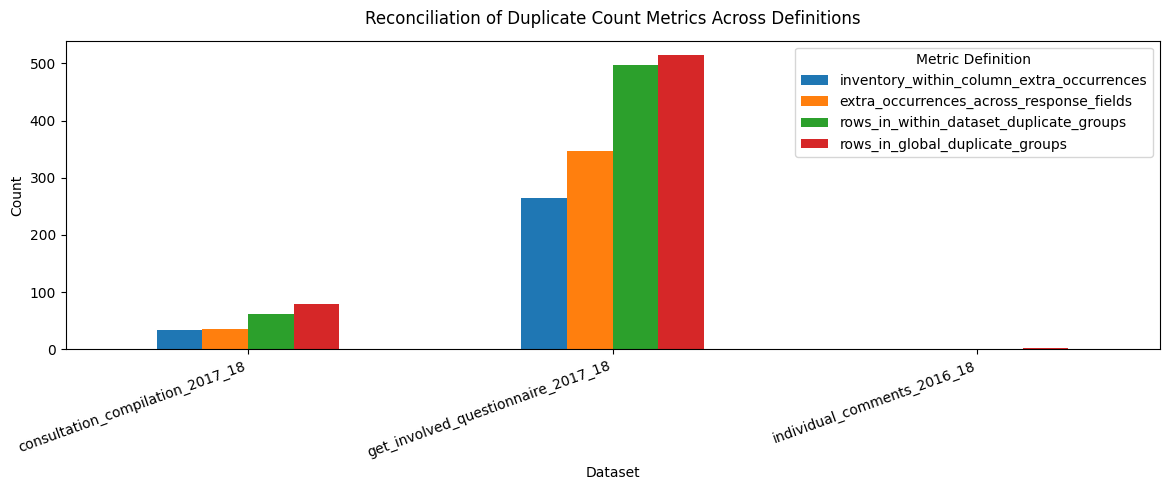

In [5]:
ax = reconciliation_df.set_index("dataset_name")[
    [
        "inventory_within_column_extra_occurrences",
        "extra_occurrences_across_response_fields",
        "rows_in_within_dataset_duplicate_groups",
        "rows_in_global_duplicate_groups",
    ]
].plot(kind="bar", figsize=(12, 5))
ax.set_title("Reconciliation of Duplicate Count Metrics Across Definitions", fontsize=12, pad=12)
ax.set_ylabel("Count")
ax.set_xlabel("Dataset")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric Definition")
plt.tight_layout()
plt.show()

## 3. Exact Duplicate Text Review File

Exact duplicate text means the normalized response string is identical. This can result from:
- Common generic answers (`'none'`, `'n/a'`, `'.'`)
- Repeated placeholder text (`'*****Personal Information Removed*****'`, `'#NAME?'`)
- Respondents submitting identical ideas across different consultation questions
- True duplicate submissions

The review file `data/interim/review/exact_duplicate_text_review.csv` contains all 596 rows in duplicate groups. It accurately links each row to its original unredacted text from the cleaned dataset (using `source_row_index`), documents group sizes and datasets, and leaves human review decision columns blank.

In [6]:
def normalize_original_column_name(column_name: str) -> str:
    text = str(column_name).replace("’", "'")
    text = re.sub(r"[^0-9A-Za-z]+", "_", text).strip("_").lower()
    return re.sub(r"_+", "_", text) or "unnamed"


column_maps = {}
for key in clean_data:
    path = INTERIM / f"{key}_column_mapping.csv"
    mapping = pd.read_csv(path, keep_default_na=False)
    column_maps[key] = dict(zip(mapping["original_column_name"], mapping["normalized_column_name"]))


def get_original_text_and_row(dataset_name: str, source_row_index: int, original_column_name: str) -> tuple[str, str]:
    df = clean_data[dataset_name]
    if source_row_index < 0 or source_row_index >= len(df):
        return "", ""
    row = df.iloc[source_row_index]
    normalized_column = column_maps[dataset_name].get(original_column_name)
    if not normalized_column or normalized_column not in df.columns:
        normalized_column = normalize_original_column_name(original_column_name)
    if normalized_column not in df.columns:
        return "", str(row.get("source_row_number", ""))
    return str(row[normalized_column]), str(row.get("source_row_number", ""))


exact_review = duplicate_text_entries.merge(
    exact_text_group_table[["text_key", "duplicate_group_id", "duplicate_group_size", "datasets"]],
    on="text_key",
    how="left",
)

original_info = [
    get_original_text_and_row(row.dataset_name, row.source_row_index, row.column_name)
    for row in exact_review.itertuples(index=False)
]
exact_review["original_text"] = [info[0] for info in original_info]
# Keep clean df source row number for exact human auditability
exact_review["source_row_number"] = [info[1] for info in original_info]

exact_review["duplicate_type"] = np.where(
    exact_review["datasets"].str.contains(","),
    "cross_dataset_exact_text",
    "within_dataset_exact_text",
)
exact_review["evidence_summary"] = exact_review.apply(
    lambda row: f"Normalized response text appears {row['duplicate_group_size']} times across dataset(s): {row['datasets']}.",
    axis=1,
)
exact_review["review_status"] = ""
exact_review["review_decision"] = ""
exact_review["review_notes"] = ""
exact_review["reviewer"] = ""

# Validate that all 596 original texts are non-empty
empty_texts = sum(1 for t in exact_review["original_text"] if not t)
assert empty_texts == 0, f"Found {empty_texts} empty original texts!"

exact_review_path = REVIEW_DIR / "exact_duplicate_text_review.csv"
exact_review.to_csv(exact_review_path, index=False, encoding="utf-8", lineterminator="\n")
print(f"Wrote {len(exact_review)} rows to {exact_review_path.relative_to(PROJECT_ROOT).as_posix()}")
display(exact_review.head(10))

Wrote 596 rows to data/interim/review/exact_duplicate_text_review.csv


,dataset_name,source_row_index,source_row_number,column_name,text_key,text_sample_redacted,duplicate_group_id,duplicate_group_size,datasets,original_text,duplicate_type,evidence_summary,review_status,review_decision,review_notes,reviewer
0,consultation_compilation_2017_18,3852,3854,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",#name?,#NAME?,exact_text_00001,2,consultation_compilation_2017_18,#NAME?,within_dataset_exact_text,Normalized response text appears 2 times across dataset(s): consultation_compilation_2017_18.,,,,
1,consultation_compilation_2017_18,4931,4933,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",#name?,#NAME?,exact_text_00001,2,consultation_compilation_2017_18,#NAME?,within_dataset_exact_text,Normalized response text appears 2 times across dataset(s): consultation_compilation_2017_18.,,,,
2,get_involved_questionnaire_2017_18,4528,4531,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government that drive your inte...",*****personal information removed*****,*****Personal Information Removed*****,exact_text_00002,2,get_involved_questionnaire_2017_18,*****Personal Information Removed*****,within_dataset_exact_text,Normalized response text appears 2 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
3,get_involved_questionnaire_2017_18,4748,4751,Q9R. Other (please specify)9,*****personal information removed*****,*****Personal Information Removed*****,exact_text_00002,2,get_involved_questionnaire_2017_18,*****Personal Information Removed*****,within_dataset_exact_text,Normalized response text appears 2 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
4,get_involved_questionnaire_2017_18,964,967,Q11R. Other: I can..,.,.,exact_text_00003,7,get_involved_questionnaire_2017_18,.,within_dataset_exact_text,Normalized response text appears 7 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
5,get_involved_questionnaire_2017_18,964,967,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government that drive your inte...",.,.,exact_text_00003,7,get_involved_questionnaire_2017_18,.,within_dataset_exact_text,Normalized response text appears 7 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
6,get_involved_questionnaire_2017_18,3525,3528,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government that drive your inte...",.,.,exact_text_00003,7,get_involved_questionnaire_2017_18,.,within_dataset_exact_text,Normalized response text appears 7 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
7,get_involved_questionnaire_2017_18,5516,5519,Q19R. Other (please specify)19,.,.,exact_text_00003,7,get_involved_questionnaire_2017_18,.,within_dataset_exact_text,Normalized response text appears 7 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
8,get_involved_questionnaire_2017_18,5516,5519,Q4R. Other (please specify)6,.,.,exact_text_00003,7,get_involved_questionnaire_2017_18,.,within_dataset_exact_text,Normalized response text appears 7 times across dataset(s): get_involved_questionnaire_2017_18.,,,,
9,get_involved_questionnaire_2017_18,5516,5519,Q6R. Other (please specify),.,.,exact_text_00003,7,get_involved_questionnaire_2017_18,.,within_dataset_exact_text,Normalized response text appears 7 times across dataset(s): get_involved_questionnaire_2017_18.,,,,


## 4. Duplicate Record Review File

Duplicate records represent entire identical rows across all original survey/consultation fields.
- Provenance columns (`source_dataset`, `source_file`, `source_row_number`) and audit metadata columns (`duplicate_text_group_id`, `exclusion_reason`) are excluded from row comparison.
- In `individual_comments_2016_18`, rows 148 to 161 (14 rows total, representing 1 group with 13 extra duplicate occurrences) are identical all-blank rows preserved from the source file.
- The other two datasets contain 0 full-row duplicate records.

The review file `data/interim/review/duplicate_record_review.csv` flags all identical records for human decision.

In [7]:
duplicate_record_frames = []
for dataset_name, df in clean_data.items():
    # Exclude provenance and audit metadata columns
    data_columns = [
        column for column in df.columns
        if column not in {"source_dataset", "source_file", "source_row_number", "duplicate_text_group_id", "exclusion_reason"}
    ]
    duplicate_mask = df[data_columns].duplicated(keep=False)
    duplicate_records = df.loc[duplicate_mask].copy()
    if duplicate_records.empty:
        continue
    duplicate_key = duplicate_records[data_columns].fillna("").astype(str).agg("||".join, axis=1)
    key_to_group = {
        key: f"dup_record_{dataset_name}_{index + 1:05d}"
        for index, key in enumerate(sorted(duplicate_key.unique()))
    }
    duplicate_records.insert(0, "duplicate_record_group_id", duplicate_key.map(key_to_group).values)
    duplicate_records.insert(1, "dataset_name", dataset_name)
    duplicate_records["duplicate_type"] = "exact_duplicate_record"
    duplicate_records["evidence_summary"] = "All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file)."
    duplicate_records["review_status"] = ""
    duplicate_records["review_decision"] = ""
    duplicate_records["review_notes"] = ""
    duplicate_records["reviewer"] = ""
    duplicate_record_frames.append(duplicate_records)

duplicate_record_review = (
    pd.concat(duplicate_record_frames, ignore_index=True)
    if duplicate_record_frames
    else pd.DataFrame(columns=["duplicate_record_group_id", "dataset_name", "duplicate_type", "evidence_summary", "review_status", "review_decision", "review_notes", "reviewer"])
)
duplicate_record_review_path = REVIEW_DIR / "duplicate_record_review.csv"
duplicate_record_review.to_csv(duplicate_record_review_path, index=False, encoding="utf-8", lineterminator="\n")
print(f"Wrote {len(duplicate_record_review)} rows to {duplicate_record_review_path.relative_to(PROJECT_ROOT).as_posix()}")
display(duplicate_record_review.head(15))

Wrote 14 rows to data/interim/review/duplicate_record_review.csv


,duplicate_record_group_id,dataset_name,source_dataset,source_file,source_row_number,duplicate_text_group_id,exclusion_reason,row_rang_e,event,v_nement,source,source_duplicate_2,source_language,langue_de_d_part,sector,secteur,public_engagement_question_also_in_compilation_question_sur_la_mobilisation_du,1_practical_idea_also_in_compilation_une_id_e_pratique_toujours_dans_compilation,3_words_3_mots,og_is_important_because_il_est_important_d_avoir_un_gouvernement_ouvert_parce_que,preferred_way_s_to_participate_in_open_government_fa_ons_pr_f_r_es_de_participer_au_gouvernement_ouvert,what_did_you_like_most_ce_que_vous_avez_le_plus_aim,dislike_ce_que_vous_avez_moins_aim,improvements_am_liorations,would_you_recommend_recommanderiez_vous,other_comments_autres_commentaires,duplicate_type,evidence_summary,review_status,review_decision,review_notes,reviewer
0,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,148,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
1,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,149,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
2,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,150,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
3,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,151,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
4,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,152,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
5,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,153,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
6,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,154,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
7,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,155,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
8,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,156,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (trailing blank records preserved from raw file).,,,,
9,dup_record_individual_comments_2016_18_00001,individual_comments_2016_18,individual_comments_2016_18,ap2016-18_individual_comments.csv,157,dup_000001,,,,,,,,,,,,,,,,,,,,,exact_duplicate_record,All original data fields are identical across rows within the dataset (tra

## 5. Near-Duplicate Review File

Near-duplicates are heuristic candidates detected using SequenceMatcher (similarity >= 0.92) across response entries between 30 and 500 characters in length. They are not exact duplicates and require human evaluation.

The review file `data/interim/review/near_duplicate_review.csv` provides pair identifiers, comparison fields, similarity ratios, redacted text samples, and empty review decision fields.

In [8]:
near_review = near_duplicate_candidates.copy()
near_review.insert(0, "near_duplicate_pair_id", [f"near_dup_{index + 1:05d}" for index in range(len(near_review))])
near_review["duplicate_type"] = "near_duplicate_candidate"
near_review["evidence_summary"] = near_review.apply(
    lambda row: f"SequenceMatcher similarity={row['similarity']} between response texts; heuristic candidate requiring human review.",
    axis=1,
)
near_review["review_status"] = ""
near_review["review_decision"] = ""
near_review["review_notes"] = ""
near_review["reviewer"] = ""
near_review_path = REVIEW_DIR / "near_duplicate_review.csv"
near_review.to_csv(near_review_path, index=False, encoding="utf-8", lineterminator="\n")
print(f"Wrote {len(near_review)} rows to {near_review_path.relative_to(PROJECT_ROOT).as_posix()}")
display(near_review.head(10))

Wrote 19 rows to data/interim/review/near_duplicate_review.csv


,near_duplicate_pair_id,left_dataset,left_row,left_column,right_dataset,right_row,right_column,similarity,left_sample_redacted,right_sample_redacted,duplicate_type,evidence_summary,review_status,review_decision,review_notes,reviewer
0,near_dup_00001,consultation_compilation_2017_18,2564,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2563,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.968,"15 DAYS LEFT to NOMINATE your deserving Community Leader, City Administrative Leader or City Council Leader's contributions with Open Data for Canada's Open...","15 DAYS LEFT to NOMINATE your deserving Community Leader, City Administrative Leader or City Council Leader's contributions with Open Data for Canada's Open...",near_duplicate_candidate,SequenceMatcher similarity=0.968 between response texts; heuristic candidate requiring human review.,,,,
1,near_dup_00002,consultation_compilation_2017_18,2680,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2682,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.921,@columgw @OpenGovCan @TBS_Canada @jaimieboyd @MelRobrt @AlexBenay @kentdaitken Awesome. Congrats!,@columgw @OpenGovCan @TBS_Canada @jaimieboyd @MelRobrt @AlexBenay @kentdaitken Welcome back!,near_duplicate_candidate,SequenceMatcher similarity=0.921 between response texts; heuristic candidate requiring human review.,,,,
2,near_dup_00003,consultation_compilation_2017_18,3231,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,4756,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.984,environmental impact assesments,Environmental impact assessments,near_duplicate_candidate,SequenceMatcher similarity=0.984 between response texts; heuristic candidate requiring human review.,,,,
3,near_dup_00004,consultation_compilation_2017_18,4406,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,4407,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.988,Financial transparency and accountability,"financial transparency and accountability,",near_duplicate_candidate,SequenceMatcher similarity=0.988 between response texts; heuristic candidate requiring human review.,,,,
4,near_dup_00005,consultation_compilation_2017_18,3321,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,3322,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.928,Great message in this opengovpart article on building bipartisan buy-in to protect openness (including shout-out to #OpenGovCan!) https://t.co/GsuEF6MUUQ ht...,Great message in this opengovpart article on building bipartisan buy-in to protect openness (including shout-out to #OpenGovCan!) https://t.co/RI3gddihLN ht...,near_duplicate_candidate,SequenceMatcher similarity=0.928 between response texts; heuristic candidate requiring human review.,,,,
5,near_dup_00006,consultation_compilation_2017_18,2731,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2732,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.962,Happy I made it to #CodeAcrossTO in time to hear the challenge presentations from all theee levels of open government (@OpenGovON/@OpenGovCan/@Open_TO) and ...,Happy I made it to #CodeAcrossTO in time to hear the challenge presentations from all three 

## 6. Cross-Dataset Row-ID Overlap Investigation

The audit identified 145 shared numeric row identifiers (`row_rang_e` in Individual Comments vs `row_ligne` in Consultation Compilation).

### Investigation Findings
1. **Row IDs are independent sequential numbers**: Both datasets independently numbered their rows starting from 1. The shared numbers (1 to 145) reflect parallel 1-based indexing in separate consultation spreadsheets, not shared database primary keys.
2. **Event and consultation source differ**: Across all 145 pairs, 0% share the same event name or collection channel (e.g. "ARMA 2016" / "Montreal 2016" vs "Future of OD EN" / "Calgary PACC").
3. **Text similarity is low**: Best pairwise string similarity across text columns shows a maximum similarity of only 0.520 (mean similarity ~0.20, with 144 of 145 pairs < 0.50). Only 2 pairs in the entire datasets share normalized text, and those are generic phrases (`'yes'`, `'no'`), not matched by row ID.
4. **Evidence Categories**:
   - `unrelated_different_event_and_text` (144 pairs): Text similarity < 0.50, different event and collection source.
   - `ambiguous_or_partial_similarity` (1 pair): Text similarity between 0.50 and 0.90, distinct events.
   - `confirmed_same_record` (0 pairs): Zero pairs exhibit high text similarity and matching metadata.

The review file `data/interim/review/cross_dataset_row_id_overlap_review.csv` documents these 145 candidate pairs with limitations, evidence summaries, and blank human review fields.

In [9]:
individual = clean_data["individual_comments_2016_18"]
compilation = clean_data["consultation_compilation_2017_18"]

individual_text_columns = [
    "public_engagement_question_also_in_compilation_question_sur_la_mobilisation_du",
    "1_practical_idea_also_in_compilation_une_id_e_pratique_toujours_dans_compilation",
    "og_is_important_because_il_est_important_d_avoir_un_gouvernement_ouvert_parce_que",
    "improvements_am_liorations",
    "other_comments_autres_commentaires",
]
compilation_text_columns = [
    "comment_question_or_idea_in_source_language_commentaire_question_ou_id_e_dans_la_langue_de_d_part",
    "comment_question_or_idea_translation_if_available_traduction_commentaire_question_ou_id_e_si_disponible",
    "subject_objet",
]

id_matches = individual.merge(
    compilation,
    left_on="row_rang_e",
    right_on="row_ligne",
    suffixes=("_individual", "_compilation"),
)

def text_similarity(a, b) -> float:
    left = re.sub(r"\s+", " ", str(a).strip().casefold())
    right = re.sub(r"\s+", " ", str(b).strip().casefold())
    if not left or not right:
        return 0.0
    if left == right:
        return 1.0
    return SequenceMatcher(None, left, right).ratio()

overlap_rows = []
for _, row in id_matches.iterrows():
    best_similarity = 0.0
    best_individual_column = ""
    best_compilation_column = ""
    best_individual_text = ""
    best_compilation_text = ""
    for individual_column in individual_text_columns:
        individual_text = row.get(individual_column, "")
        if not str(individual_text).strip():
            continue
        for compilation_column in compilation_text_columns:
            compilation_text = row.get(compilation_column, "")
            if not str(compilation_text).strip():
                continue
            similarity = text_similarity(individual_text, compilation_text)
            if similarity > best_similarity:
                best_similarity = similarity
                best_individual_column = individual_column
                best_compilation_column = compilation_column
                best_individual_text = str(individual_text)
                best_compilation_text = str(compilation_text)

    individual_event = row.get("event", "")
    compilation_event = row.get("event_v_nement", "")
    individual_source = row.get("source_individual", "")
    compilation_source = row.get("source_compilation", "")
    individual_language = row.get("source_language_individual", "")
    compilation_language = row.get("source_language_compilation", "")

    event_same = bool(individual_event and compilation_event and individual_event.strip().lower() == compilation_event.strip().lower())
    source_same = bool(individual_source and compilation_source and individual_source.strip().lower() == compilation_source.strip().lower())
    language_same = bool(individual_language and compilation_language and individual_language.strip().lower() == compilation_language.strip().lower())

    if best_similarity >= 0.95 and (event_same or source_same):
        evidence_category = "confirmed_same_record"
        limitation = "High text similarity and matching event/source; requires human confirmation before merge."
    elif best_similarity >= 0.90:
        evidence_category = "same_text_different_record"
        limitation = "High text similarity but event/source differ; likely repeated phrase across distinct contexts."
    elif best_similarity >= 0.50:
        evidence_category = "ambiguous_or_partial_similarity"
        limitation = "Partial text overlap (similarity between 0.50 and 0.90); distinct events and sources."
    else:
        evidence_category = "unrelated_different_event_and_text"
        limitation = "Independent sequential integer row numbering; text similarity < 0.50, events and sources differ."

    overlap_rows.append({
        "overlap_pair_id": f"row_id_overlap_{len(overlap_rows) + 1:05d}",
        "shared_row_id": row.get("row_rang_e", ""),
        "individual_source_row_number": row.get("source_row_number_individual", ""),
        "compilation_source_row_number": row.get("source_row_number_compilation", ""),
        "individual_event": individual_event,
        "compilation_event": compilation_event,
        "individual_source": individual_source,
        "compilation_source": compilation_source,
        "individual_language": individual_language,
        "compilation_language": compilation_language,
        "event_same": event_same,
        "source_same": source_same,
        "language_same": language_same,
        "best_text_similarity": round(best_similarity, 3),
        "best_individual_column": best_individual_column,
        "best_compilation_column": best_compilation_column,
        "individual_text_original": best_individual_text,
        "compilation_text_original": best_compilation_text,
        "evidence_category": evidence_category,
        "evidence_summary": f"Shared ID={row.get('row_rang_e', '')}; best text similarity={best_similarity:.3f}; event_same={event_same}; source_same={source_same}; language_same={language_same}.",
        "limitations": limitation,
        "review_status": "",
        "review_decision": "",
        "review_notes": "",
        "reviewer": "",
    })

cross_dataset_overlap_review = pd.DataFrame(overlap_rows)
cross_dataset_overlap_path = REVIEW_DIR / "cross_dataset_row_id_overlap_review.csv"
cross_dataset_overlap_review.to_csv(cross_dataset_overlap_path, index=False, encoding="utf-8", lineterminator="\n")
print(f"Wrote {len(cross_dataset_overlap_review)} rows to {cross_dataset_overlap_path.relative_to(PROJECT_ROOT).as_posix()}")
display(cross_dataset_overlap_review.head(10))

Wrote 145 rows to data/interim/review/cross_dataset_row_id_overlap_review.csv


,overlap_pair_id,shared_row_id,individual_source_row_number,compilation_source_row_number,individual_event,compilation_event,individual_source,compilation_source,individual_language,compilation_language,event_same,source_same,language_same,best_text_similarity,best_individual_column,best_compilation_column,individual_text_original,compilation_text_original,evidence_category,evidence_summary,limitations,review_status,review_decision,review_notes,reviewer
0,row_id_overlap_00001,35,2,4997,ARMA 2016,Future of OD EN,Indv Comment,WebEx Chat,English,English,False,False,True,0.331,og_is_important_because_il_est_important_d_avoir_un_gouvernement_ouvert_parce_que,comment_question_or_idea_in_source_language_commentaire_question_ou_id_e_dans_la_langue_de_d_part,I need to understand what this intiative means to accomplish,Ensure all have a way to report issues identified re. quality,unrelated_different_event_and_text,Shared ID=35; best text similarity=0.331; event_same=False; source_same=False; language_same=True.,"Independent sequential integer row numbering; text similarity < 0.50, events and sources differ.",,,,
1,row_id_overlap_00002,91,3,2330,Montreal 2016,Future of OD EN,Indv Comment,WebEx Chat,English,English,False,False,True,0.214,og_is_important_because_il_est_important_d_avoir_un_gouvernement_ouvert_parce_que,comment_question_or_idea_in_source_language_commentaire_question_ou_id_e_dans_la_langue_de_d_part,Je m’intéresse aux contextes de développement des données ouvertes et du web sémantique. RT: I am interested in the production of open data and the web sema...,"suggested datasets based on what others have searched, much like amazon",unrelated_different_event_and_text,Shared ID=91; best text similarity=0.214; event_same=False; source_same=False; language_same=True.,"Independent sequential integer row numbering; text similarity < 0.50, events and sources differ.",,,,
2,row_id_overlap_00003,101,4,2336,Ottawa 2016,Future of OD EN,Indv Comment,WebEx Chat,English,English,False,False,True,0.296,1_practical_idea_also_in_compilation_une_id_e_pratique_toujours_dans_compilation,comment_question_or_idea_in_source_language_commentaire_question_ou_id_e_dans_la_langue_de_d_part,Data I want button on each department website with voting-- get at questions lots of people ask.,cross-promotion of blog on social media handles that are broadly followed,unrelated_different_event_and_text,Shared ID=101; best text similarity=0.296; event_same=False; source_same=False; language_same=True.,"Independent sequential integer row numbering; text similarity < 0.50, events and sources differ.",,,,
3,row_id_overlap_00004,146,5,5122,Whitehorse 2016,Calgary PACC,Indv Comment,Slido Text,S,English,False,False,False,0.286,improvements_am_liorations,comment_question_or_idea_in_source_language_commentaire_question_ou_id_e_dans_la_langue_de_d_part,too short,Ditto,unrelated_different_event_and_text,Shared ID=146; best text similarity=0.286; event_same=False; source_same=False; language_same=False.,"Independent sequential integer row numbering; text similarity < 0.50, events and sources differ.",,,,
4,row_id_overlap_00005,26,6,4233,ARMA 2016,Future of OD EN,Indv Comment,WebEx Chat,English,English,False,False,True,0.353,public_engagement_question_also_in_compilation_question_sur_la_mobilisation_du,subject_objet,Preservation of open government information and data. Is there an opportunity to collaborate in other sectors (universities?),Conversation about Locating tools/ Directives,unrelated_different_event_and_text,Shared ID=26; best text similarity=0.353; event_same=False; source_same=False; language_same=True.,"Independent sequential integer row numbering; text similarity < 0.50, events and sources differ.",,,,
5,row_id_overlap_00006,16,7,4593,ARMA 2016,Future of OD EN,Indv Comment,WebEx Chat,English,English,False,False,True,0.291,public_engagement_question_also_in_compilation_question_sur_la_mobilisation_du,comment_question_or_idea_in_source_language_commentaire_question

## 7. Manual Review Protocol and Decision Matrix

The review tables generated above are designed for standardized human annotation:

| Field | Expected Format / Values | Purpose |
|---|---|---|
| `review_status` | `pending`, `in_progress`, `completed` | Tracking review progress |
| `review_decision` | `keep_both`, `mark_duplicate`, `merge_records`, `flag_placeholder` | Decision on how record should be handled |
| `review_notes` | Free text | Rationale, domain context, or policy implications |
| `reviewer` | Annotator name / ID | Provenance for research reproducibility |

### Decision Guidelines
- **Exact Text Duplicates**: Distinguish between repeated substantive citizen feedback (keep both as genuine repeated public interest) vs placeholder / boilerplate responses (flag placeholder).
- **Duplicate Records**: The 14 trailing records in Individual Comments are all-blank rows; reviewers can safely designate them as trailing blanks.
- **Near-Duplicates**: Reviewers should evaluate whether near-duplicate pairs represent duplicate submissions by the same entity or independent similar thoughts by different citizens.
- **Shared Row IDs**: Because all 145 shared IDs reflect independent row numbering across unrelated consultations, reviewers should default to `keep_both`.

## 8. Summary Report and Output Generation

In [10]:
def format_markdown_table(df: pd.DataFrame) -> str:
    # Format a DataFrame as a GitHub-flavored Markdown table without requiring tabulate.
    headers = [str(col) for col in df.columns]
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for _, row in df.iterrows():
        row_str = [str(val).replace("|", "\\|").replace("\n", " ") for val in row]
        lines.append("| " + " | ".join(row_str) + " |")
    return "\n".join(lines)


review_file_summary = pd.DataFrame([
    {"review_file": exact_review_path.relative_to(PROJECT_ROOT).as_posix(), "rows": len(exact_review), "purpose": "Exact duplicate normalized response text (596 rows across duplicate groups)."},
    {"review_file": duplicate_record_review_path.relative_to(PROJECT_ROOT).as_posix(), "rows": len(duplicate_record_review), "purpose": "Exact duplicate full cleaned records (14 trailing blank rows in Individual Comments)."},
    {"review_file": near_review_path.relative_to(PROJECT_ROOT).as_posix(), "rows": len(near_review), "purpose": "Heuristic near-duplicate text pairs (19 pairs)."},
    {"review_file": cross_dataset_overlap_path.relative_to(PROJECT_ROOT).as_posix(), "rows": len(cross_dataset_overlap_review), "purpose": "Shared row-ID overlap between Individual Comments and Consultation Compilation (145 pairs)."},
])
display(review_file_summary)

overlap_category_counts = (
    cross_dataset_overlap_review["evidence_category"]
    .value_counts()
    .rename_axis("evidence_category")
    .reset_index(name="count")
)
display(overlap_category_counts)

report_lines = [
    "# Duplicate and Overlap Manual Review Report",
    "",
    "Generated by `notebooks/02_duplicate_overlap_review.ipynb`.",
    "",
    "## 1. Count Reconciliation",
    "",
    "- `inventory_within_column_extra_occurrences`: extra repeated values counted separately within each response-like column (matches `data_inventory.csv`).",
    "- `extra_occurrences_across_response_fields`: extra repeated values after pooling response-like fields within each dataset.",
    "- `rows_in_within_dataset_duplicate_groups`: count of rows whose normalized response text appears at least twice within the same dataset.",
    "- `rows_in_global_duplicate_groups`: count of all rows whose normalized text appears at least twice across the collection (stored in `government_duplicate_text_entries.csv`).",
    "- `duplicate_groups_touched`: count of unique duplicate normalized text groups represented in each dataset.",
    "",
    format_markdown_table(reconciliation_df),
    "",
    "## 2. Cross-Dataset Row-ID Overlap Categories (145 Shared IDs)",
    "",
    "- Shared numeric row IDs (1 to 145) reflect independent sequential integer row numbering, NOT foreign keys or shared respondents.",
    "- 0 out of 145 pairs share the same event name or consultation channel.",
    "- Pairwise text similarity has a maximum of only 0.520 (mean similarity ~0.20, with 144 of 145 pairs < 0.50).",
    "",
    format_markdown_table(overlap_category_counts),
    "",
    "## 3. Review Files",
    "",
    format_markdown_table(review_file_summary),
    "",
    "## 4. Methodological Boundaries and Limitations",
    "",
    "- Evidence categories and similarity ratios are algorithmic screening aids, not definitive human review decisions.",
    "- Shared row IDs alone are not sufficient to prove record identity.",
    "- Generic or boilerplate responses (e.g. `'none'`, `'n/a'`, `'.'`) inflate exact-text duplicate counts.",
    "- All source and cleaned datasets remain completely unchanged: no records were deleted, merged, or relabeled.",
]

review_report_path = REPORTS / "duplicate_overlap_review_report.md"
review_report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"Wrote report to {review_report_path.relative_to(PROJECT_ROOT).as_posix()}")

,review_file,rows,purpose
0,data/interim/review/exact_duplicate_text_review.csv,596,Exact duplicate normalized response text (596 rows across duplicate groups).
1,data/interim/review/duplicate_record_review.csv,14,Exact duplicate full cleaned records (14 trailing blank rows in Individual Comments).
2,data/interim/review/near_duplicate_review.csv,19,Heuristic near-duplicate text pairs (19 pairs).
3,data/interim/review/cross_dataset_row_id_overlap_review.csv,145,Shared row-ID overlap between Individual Comments and Consultation Compilation (145 pairs).


,evidence_category,count
0,unrelated_different_event_and_text,144
1,ambiguous_or_partial_similarity,1


Wrote report to reports/duplicate_overlap_review_report.md


## 9. Automated Validation

The review workflow asserts:
1. All 4 review CSV files and the Markdown summary report exist and have non-zero size.
2. All review files contain the 4 standardized human review fields (`review_status`, `review_decision`, `review_notes`, `reviewer`).
3. All human review fields are strictly blank (empty string) before human review.
4. Row counts match expected totals:
   - Exact duplicate text review: 596 rows
   - Duplicate record review: 14 rows
   - Near-duplicate candidate review: 19 rows
   - Cross-dataset row-ID overlap review: 145 rows

In [11]:
required_review_files = [
    exact_review_path,
    duplicate_record_review_path,
    near_review_path,
    cross_dataset_overlap_path,
    review_report_path,
]
for path in required_review_files:
    assert path.exists() and path.stat().st_size > 0, f"Missing review output: {path}"

for frame_name, frame in {
    "exact_review": exact_review,
    "duplicate_record_review": duplicate_record_review,
    "near_review": near_review,
    "cross_dataset_overlap_review": cross_dataset_overlap_review,
}.items():
    for column in ["review_status", "review_decision", "review_notes", "reviewer"]:
        assert column in frame.columns, f"{frame_name} missing {column}"
        assert frame[column].fillna("").eq("").all(), f"{frame_name}.{column} should be blank before human review"

assert len(exact_review) == 596, f"Expected 596 exact review rows, got {len(exact_review)}"
assert len(duplicate_record_review) == 14, f"Expected 14 duplicate record review rows, got {len(duplicate_record_review)}"
assert len(near_review) == 19, f"Expected 19 near-duplicate review rows, got {len(near_review)}"
assert len(cross_dataset_overlap_review) == 145, f"Expected 145 shared row-ID candidates, got {len(cross_dataset_overlap_review)}"

print("All validation checks passed successfully!")
print(f"Review files verified in: {REVIEW_DIR.relative_to(PROJECT_ROOT).as_posix()}")

All validation checks passed successfully!
Review files verified in: data/interim/review
